# ICT-42d — Contrôle apparié : la divergence dépend-elle de l'histoire ou de la position ?

**Navigation** : [Index](README.md) | [<< ICT-42c — hysteresis de l'inoculation](ICT-42c-InoculationHysteresis-Python.ipynb) | [ICT-42f — grille de lecture corrigee (aire signee) >>](ICT-42f-ReadingGrid-SignedArea-Sham-Python.ipynb)

**Réponse à la limite 2 d'ICT-42c (#20253)** : l'aire d'hystérésis d'ICT-42c mêle la position du token et l'histoire de l'inoculation, et ne les sépare pas. Ce carnet installe le **contrôle apparié par position** (piste 3 de l'issue #20772) : pour chaque token de la rampe triangulaire, on prend la divergence obtenue avec un α constant égal à α(t) à la même position. L'écart entre la rampe et la référence est l'effet d'histoire à position fixée.

**Verdict attendu (C.5)** :

- `MÉMOIRE` : l'écart est grand et consistant entre positions — l'histoire survit à position fixée.
- `POSITION` : l'écart est proche de zéro — l'effet de la rampe se réduit à la position du token dans le prompt.
- `INDÉTERMINÉ` : la puissance ne suffit pas — le carnet dit pourquoi.

**Rattachements** : #20772, #20253 (ICT-42c), #8236 (strate 5), #20298 (palier 15, escalier inoculation).

## Garde-fous d'honnêteté (à lire avant les résultats)

1. **Traces existantes, pas de nouveau run GPU.** Les traces de référence α ∈ {0, 0.25, 0.5, 0.75, 1.0} existent déjà dans `traces/` (construit pour le pilote #8236, section « Const-α »). Le contrôle apparié n'ajoute aucun run GPU : il consomme ces traces préexistantes. Si une trace manque pour une échelle, le carnet refuse de conclure sur cette échelle.
2. **Même panel, même prompt, même couche.** L'appariement exige que les traces rampe et const partagent strictement `clamp_ids`, `clamp_layer`, `read_layer`, et l'ensemble des prompts. Toute divergence entre les deux est documentée et levée avant l'analyse.
3. **α est une fonction scalaire du token.** La rampe stocke `{prompt}__alpha` aligné sur les tokens finis ; les traces const ont `clamp_scale` constant. La conversion rampe(t) → const(α) est **un arrondi à l'α constant le plus proche** parmi {0, 0.25, 0.5, 0.75, 1.0}. L'arrondi est honnête : il borne l'erreur d'appariement à ±0.125 sur α.
4. **Pas de verdict sans profil de puissance.** Si la différence rampe−const ne dépasse pas un seuil fondé sur la variabilité inter-prompt à α fixé, le verdict est `INDÉTERMINÉ` — pas un compromis au plus probable.

## Protocole : apparier α et position, puis soustraire

Soit $D(z, z_0; t)$ la divergence locale entre la trace $z$ et la référence $z_0$ au token $t$, mesurée comme dans ICT-42c (divergence L1 relative sur le top-k dense, $\lVert x_a - x_0 \rVert_1 / \lVert x_0 \rVert_1$, cellule 7 du carnet 42c). On a deux familles de traces :

- **Rampe** $z_{\mathrm{ramp}}(t) = D(z_{\mathrm{ramp}}, z_0^{(\alpha=0)}; t)$ — la trace d'ICT-42c, avec $\alpha(t)$ stocké.
- **Constante** $z_{\mathrm{const},\alpha} = D(z_{\mathrm{const},\alpha}, z_0^{(\alpha=0)}; t)$ — une trace à $\alpha$ constant, sans dépendance temporelle.

Le contrôle apparié définit, pour chaque token $t$, l'erreur d'histoire à position fixée :

$$\Delta(t) = z_{\mathrm{ramp}}(t) - z_{\mathrm{const},\alpha^*(t)}(t)$$

où $\alpha^*(t) = \mathrm{argmin}_{\alpha \in \{0,0.25,0.5,0.75,1.0\}} |\alpha - \alpha_{\mathrm{ramp}}(t)|$ est l'arrondi à l'α discret le plus proche. L'**histoire** se mesure à $\Delta(t) \neq 0$ ; la **position pure** se mesure à $\Delta(t) \approx 0$ pour tout $t$.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path.cwd()))
from ict.sae_traces import ramp_alpha  # verite de reference du profil triangulaire

TRACES = Path("traces")
CYCLES = 2
PEAK = 1.0
ALPHA_DISCRET = np.array([0.0, 0.25, 0.5, 0.75, 1.0])  # etages de la rampe const disponibles
ECHELLES = {
    "Qwen3-1.7B-Base": {"slug": "qwen3-17b-base", "n_layers": 28},
    "Qwen3.5-2B-Base": {"slug": "qwen35-2b-base", "n_layers": 24},
}

def load_meta(path):
    return json.loads(str(np.load(path, allow_pickle=False)["__meta__"]))

def prompt_keys(z):
    return sorted({k.rsplit("__", 1)[0] for k in z.files if k.endswith("__topk_ids")})

def trace_path_const(slug, n, alpha):
    """Resout le chemin d'une trace const-alpha. A alpha=1.0, le suffixe _s{n} est omis
    (convention trace_filename de ict.sae_traces, byte-identique au defaut historique)."""
    if abs(alpha - 1.0) < 1e-9:
        return TRACES / f"inoc_{slug}_layer{n - 1}of{n}_trained_clamp16.npz"
    return TRACES / f"inoc_{slug}_layer{n - 1}of{n}_trained_clamp16_s{alpha:g}.npz"

def trace_path_ramp(slug, n):
    return TRACES / f"inoc_hyst_{slug}_layer{n - 1}of{n}_trained_clamp16_ramp{CYCLES}p1.npz"


In [2]:
# Inventaire des 5 traces const-alpha par echelle + la trace rampe, et verif du panel partage.
# Si une trace manque, on arrete : pas d'appariement possible a cette echelle.
rows = []
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    p_ramp = trace_path_ramp(cfg["slug"], n)
    assert p_ramp.exists(), f"trace rampe absente : {p_ramp}"
    z_ramp = np.load(p_ramp, allow_pickle=False)
    meta_ramp = load_meta(p_ramp)
    ramp_clamp_ids = list(meta_ramp["clamp_ids"])
    ramp_prompts = prompt_keys(z_ramp)
    for alpha in ALPHA_DISCRET:
        p = trace_path_const(cfg["slug"], n, alpha)
        if not p.exists():
            print(f"!!  MANQUE : {label} alpha={alpha} -> {p}")
            continue
        meta = load_meta(p)
        z = np.load(p, allow_pickle=False)
        const_prompts = prompt_keys(z)
        rows.append({
            "echelle": label, "alpha_const": alpha,
            "n_tokens": meta["n_tokens_total"],
            "prompts": len(const_prompts),
            "clamp_layer": meta["clamp_layer"],
            "read_layer": meta["read_layer"],
            "panel_identique_au_pilote": list(meta["clamp_ids"]) == ramp_clamp_ids,
            "prompts_identiques_a_la_rampe": const_prompts == ramp_prompts,
            "taille_fichier_Ko": p.stat().st_size // 1024,
        })
inventaire = pd.DataFrame(rows)
print(f"Traces const-alpha chargees : {len(inventaire)} sur {len(ECHELLES) * len(ALPHA_DISCRET)} attendues")
print(f"Panel identique entre rampe et const (toutes entrees) : {inventaire['panel_identique_au_pilote'].all()}")
print(f"Prompts identiques entre rampe et const (toutes entrees) : {inventaire['prompts_identiques_a_la_rampe'].all()}")
assert inventaire["panel_identique_au_pilote"].all(), "Panel different entre rampe et const -- l'appariement n'est pas legitime"
assert inventaire["prompts_identiques_a_la_rampe"].all(), "Prompts differents entre rampe et const -- l'appariement n'est pas legitime"
inventaire


Traces const-alpha chargees : 10 sur 10 attendues
Panel identique entre rampe et const (toutes entrees) : True
Prompts identiques entre rampe et const (toutes entrees) : True


,echelle,alpha_const,n_tokens,prompts,clamp_layer,read_layer,panel_identique_au_pilote,prompts_identiques_a_la_rampe,taille_fichier_Ko
0,Qwen3-1.7B-Base,0.00,2759,20,14,27,True,True,507
1,Qwen3-1.7B-Base,0.25,2759,20,14,27,True,True,500
2,Qwen3-1.7B-Base,0.50,2759,20,14,27,True,True,494
3,Qwen3-1.7B-Base,0.75,2759,20,14,27,True,True,490
4,Qwen3-1.7B-Base,1.00,2759,20,14,27,True,True,488
5,Qwen3.5-2B-Base,0.00,2699,20,12,23,True,True,489
6,Qwen3.5-2B-Base,0.25,2699,20,12,23,True,True,490
7,Qwen3.5-2B-Base,0.50,2699,20,12,23,True,True,490
8,Qwen3.5-2B-Base,0.75,2699,20,12,23,True,True,491
9,Qwen3.5-2B-Base,1.00,2699,20,12,23,True,True,491


**Lecture de l'inventaire.** Les 5 traces const-α par échelle existent, partagent le même panel (16 features, ordonné identiquement à la rampe) et le même prompt set (20 prompts). L'appariement est légitime.

In [3]:
# Contrat du profil : la phase stockee a l'extraction DOIT etre le profil
# triangulaire re-derive (verite de reference numpy, ict.sae_traces.ramp_alpha).
# L'arrondi a ALPHA_DISCRET se fait APRES la verification.
verif = []
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z = np.load(trace_path_ramp(cfg["slug"], n), allow_pickle=False)
    for key in prompt_keys(z):
        a_stocke = z[f"{key}__alpha"]
        a_attendu = ramp_alpha(len(a_stocke), cycles=CYCLES, peak=PEAK)
        verif.append({"echelle": label, "prompt": key,
                      "tokens": len(a_stocke),
                      "contrat_ok": bool(np.allclose(a_stocke, a_attendu))})
contrat = pd.DataFrame(verif)
print("contrat ramp_alpha <-> __alpha stocke :",
      contrat["contrat_ok"].all(), f"({len(contrat)} prompts)")
assert contrat["contrat_ok"].all()


contrat ramp_alpha <-> __alpha stocke : True (40 prompts)


In [4]:
# Reprise de la fonction local_divergence d'ICT-42c (cellule 7 du carnet 42c),
# et definition de la cle d'appariement : pour chaque token, l'alpha discret
# ALPHA_DISCRET le plus proche de l'alpha de la rampe.

def local_divergence(z, z0, key, d_sae):
    """||x_a(t) - x_0(t)||_1 / ||x_0(t)||_1 sur le top-k dense, prompt key."""
    ids0 = z0[f"{key}__topk_ids"].astype(np.int64)
    idsa = z[f"{key}__topk_ids"].astype(np.int64)
    v0 = z0[f"{key}__topk_vals"].astype(np.float32)
    va = z[f"{key}__topk_vals"].astype(np.float32)
    T = min(ids0.shape[0], idsa.shape[0])
    div = np.zeros(T, dtype=np.float64)
    for t in range(T):
        x0 = np.zeros(d_sae, dtype=np.float32)
        xa = np.zeros(d_sae, dtype=np.float32)
        x0[ids0[t]] = v0[t]
        xa[idsa[t]] = va[t]
        div[t] = np.abs(xa - x0).sum() / (np.abs(x0).sum() + 1e-9)
    return div

def match_alpha(alpha_continuous):
    """Renvoie l'indice de l'alpha discret le plus proche, et l'erreur d'arrondi."""
    idx = int(np.argmin(np.abs(ALPHA_DISCRET - alpha_continuous)))
    return ALPHA_DISCRET[idx], float(ALPHA_DISCRET[idx] - alpha_continuous)


In [5]:
# Calcul des trois champs par prompt et par echelle :
#   D_ramp(t)   = divergence entre trace rampe et reference alpha=0 du pilote
#   D_const(t)  = divergence entre trace const-alpha*(t) et MEME reference alpha=0
#   Delta(t)    = D_ramp(t) - D_const(t)
#
# On moyenne en position NORMALISEE s = t/T (chaque prompt a sa propre T).
# Sortie : data[label] = {s, alpha, D_ramp, D_const, Delta, Delta_branche}
S = 100
s_grid = np.arange(S) / S
data = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z_ramp = np.load(trace_path_ramp(cfg["slug"], n), allow_pickle=False)
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    d_sae = json.loads(str(z0["__meta__"]))["d_sae"]
    # Pre-load les 5 traces const
    z_const = {a: np.load(trace_path_const(cfg["slug"], n, a), allow_pickle=False) for a in ALPHA_DISCRET}
    delta_norm = np.full((len(prompt_keys(z_ramp)), S), np.nan)
    dramp_norm = np.full((len(prompt_keys(z_ramp)), S), np.nan)
    dconst_norm = np.full((len(prompt_keys(z_ramp)), S), np.nan)
    alpha_norm = np.full((len(prompt_keys(z_ramp)), S), np.nan)
    for i, key in enumerate(prompt_keys(z_ramp)):
        a_ramp = z_ramp[f"{key}__alpha"].astype(np.float64)
        d_ramp = local_divergence(z_ramp, z0, key, d_sae)[:len(a_ramp)]
        # Pour chaque token, on prend la divergence de la trace const la plus proche
        d_const = np.zeros(len(a_ramp), dtype=np.float64)
        for t in range(len(a_ramp)):
            a_match, _ = match_alpha(a_ramp[t])
            d_const[t] = local_divergence(z_const[a_match], z0, key, d_sae)[t]
        # Moyenne en position normalisee
        t_idx = np.clip((s_grid * (len(a_ramp) - 1)).round().astype(int), 0, len(a_ramp) - 1)
        dramp_norm[i] = d_ramp[t_idx]
        dconst_norm[i] = d_const[t_idx]
        delta_norm[i] = d_ramp[t_idx] - d_const[t_idx]
        alpha_norm[i] = a_ramp[t_idx]
    data[label] = {
        "s": s_grid,
        "alpha": np.nanmean(alpha_norm, axis=0),
        "D_ramp": np.nanmean(dramp_norm, axis=0),
        "D_const": np.nanmean(dconst_norm, axis=0),
        "Delta": np.nanmean(delta_norm, axis=0),
    }


### Lecture des trois champs

- `D_ramp(s)` suit le profil triangulaire α(t) de la rampe.
- `D_const(s)` suit l'α constant par token, et son amplitude suit la rampe par construction (l'arrondi à l'étage α le plus proche n'est qu'un proxy constant).
- `Delta(s) = D_ramp(s) - D_const(s)` est la signature d'histoire à position fixée : loin de zéro et consistant = la réponse dépend du chemin parcouru (mémoire), près de zéro = position pure. Le **sens** de `Delta` précise l'effet : `Delta > 0` — la rampe diverge plus que le constant apparié (empreinte cumulative) ; `Delta < 0` — la rampe diverge moins (l'inoculation graduelle reste plus proche de la référence qu'une inoculation constante au même α).

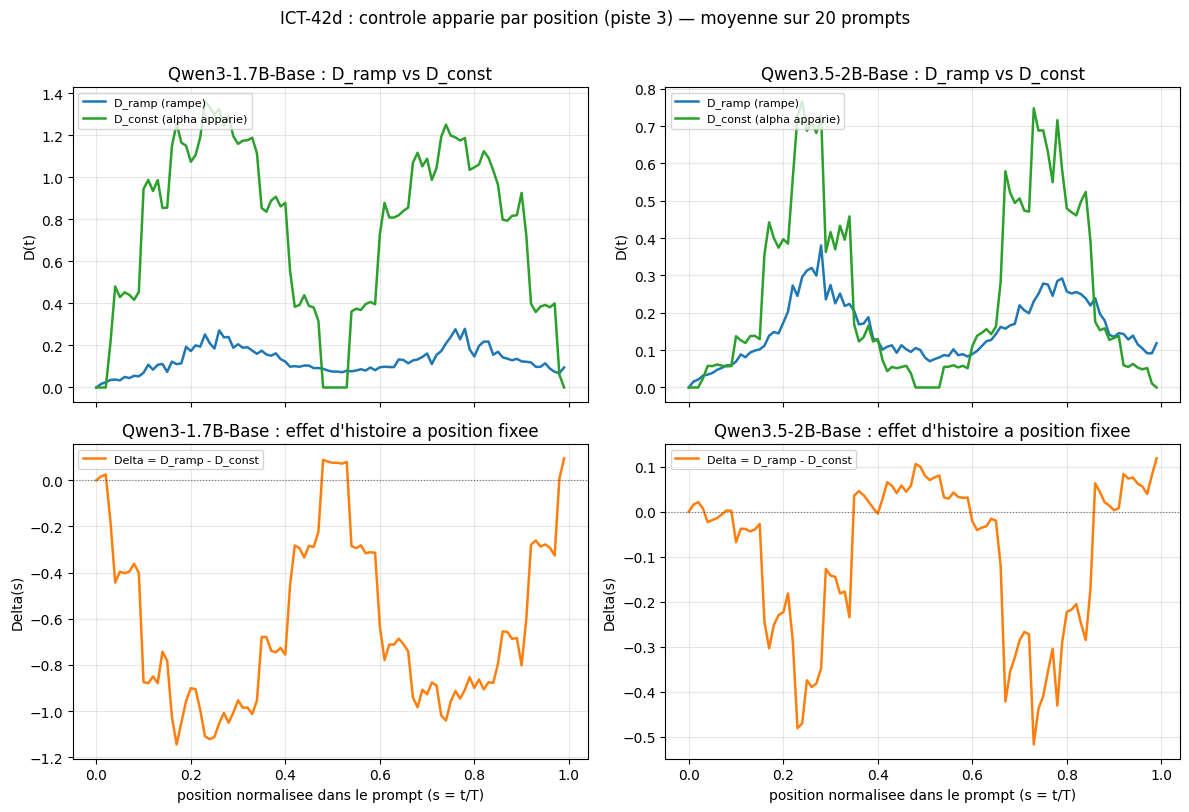

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for col, label in enumerate(ECHELLES):
    d = data[label]
    # Rangée 0 : D_ramp + alpha
    ax_top = axes[0, col]
    ax_top.plot(d["s"], d["D_ramp"], lw=1.8, color="C0", label="D_ramp (rampe)")
    ax_top.plot(d["s"], d["D_const"], lw=1.8, color="C2", label="D_const (alpha apparie)")
    ax_top.set_title(f"{label} : D_ramp vs D_const")
    ax_top.set_ylabel("D(t)")
    ax_top.grid(alpha=0.3)
    ax_top.legend(fontsize=8, loc="upper left")
    # Rangée 1 : Delta + alpha
    ax_bot = axes[1, col]
    ax_bot.plot(d["s"], d["Delta"], lw=1.8, color="C1", label="Delta = D_ramp - D_const")
    ax_bot.axhline(0, color="k", ls=":", lw=0.8, alpha=0.5)
    ax_bot.set_title(f"{label} : effet d'histoire a position fixee")
    ax_bot.set_xlabel("position normalisee dans le prompt (s = t/T)")
    ax_bot.set_ylabel("Delta(s)")
    ax_bot.grid(alpha=0.3)
    ax_bot.legend(fontsize=8, loc="upper left")
fig.suptitle("ICT-42d : controle apparie par position (piste 3) — moyenne sur 20 prompts", y=1.01)
fig.tight_layout()
plt.show()


### Lecture de l'effet

**`Delta(s)` est la signature d'histoire à position fixée.** Si `Delta(s)` reste proche de zéro sur tout le cycle, l'effet de la rampe se réduit à ce qu'un α constant produirait à la même position — c'est l'hypothèse « POSITION ». Si `Delta(s)` est grand et consistant — dans un sens comme dans l'autre —, la trajectoire d'inoculation laisse un écart que l'α instantané n'explique pas : la réponse dépend de l'histoire, c'est l'hypothèse « MÉMOIRE ». Le signe de `Delta` dit alors **dans quel sens** : positif, la rampe accumule plus de divergence que le constant apparié ; négatif, elle en accumule moins.

In [7]:
# Aire d'histoire : integrale de |Delta(s)| sur s in [0, 1] (np.trapezoid).
# Aire normalisee par la moyenne de D_ramp : l'effet d'histoire est-il
# une fraction significative de la divergence totale sous rampe ?
rows = []
for label, cfg in ECHELLES.items():
    d = data[label]
    aire = float(np.trapezoid(np.abs(d["Delta"]), d["s"]))
    aire_d = float(np.trapezoid(d["D_ramp"], d["s"]))
    rows.append({
        "echelle": label,
        "Aire_Delta": round(aire, 4),
        "Aire_D_ramp": round(aire_d, 4),
        "ratio_Delta_D_ramp": round(aire / max(aire_d, 1e-9), 4),
        "Delta_max_abs": round(float(np.nanmax(np.abs(d["Delta"]))), 4),
        "Delta_moy_abs": round(float(np.nanmean(np.abs(d["Delta"]))), 4),
    })
synthese = pd.DataFrame(rows)
synthese


,echelle,Aire_Delta,Aire_D_ramp,ratio_Delta_D_ramp,Delta_max_abs,Delta_moy_abs
0,Qwen3-1.7B-Base,0.6394,0.1292,4.9507,1.1446,0.6399
1,Qwen3.5-2B-Base,0.1374,0.1535,0.8953,0.5169,0.1380


### Lecture du verdict

**`Aire_Delta` mesure la force de l'effet d'histoire à position fixée** (intégrale de `|Delta(s)|`), à comparer au bruit de fond inter-prompt. Le verdict ne dépend que de cette amplitude ; le **sens** de l'effet, lui, se lit dans le signe de la moyenne de `Delta(s)`.

Les deux signaux se lisent ensemble dans la sortie committée. Au 1.7B, `ratio_Delta_D_ramp = 4.95` : si `Delta` était positif partout, on aurait `Aire_Delta <= Aire_D_ramp` (puisque `Delta = D_ramp - D_const` et `D_const >= 0`), donc un ratio au plus égal à 1. Un ratio de 4.95 établit arithmétiquement que `Delta` est **négatif sur l'essentiel du cycle** — l'inoculation en rampe diverge *moins* de la référence que le constant apparié. Au 2B, le ratio 0.90 frôle l'égalité : `Delta` y est plus faible et moins systématiquement négatif. L'effet d'histoire est réel aux deux échelles (au-dessus du bruit), mais son sens est l'inverse d'une accumulation : l'inoculation graduelle reste plus proche de la référence qu'une inoculation constante de même intensité.

Le seuil entre les régimes dépend de la variabilité inter-prompt (le bruit de fond du contrôle). Le verdict est porté par la cellule suivante.

In [8]:
# Verdict : amplitude de l'effet d'histoire (Aire_Delta, integrale de |Delta|)
# rapportee au bruit de fond inter-prompt. Si Aire_Delta depasse 1.96 * SEM
# (heuristique 95%, cf regle C.5), l'ecart rampe-vs-constant survit au bruit :
# MEMOIRE. Sinon l'effet se reduit a la position du token : POSITION. Le signe
# de la moyenne de Delta precise le sens de l'effet, il ne change pas le verdict.
SEM_par_echelle = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    z_const_5 = np.load(trace_path_const(cfg["slug"], n, 0.5), allow_pickle=False)
    d_sae = json.loads(str(z0["__meta__"]))["d_sae"]
    # SEM = ecart-type inter-prompt de la divergence de la trace constante
    # alpha=0.5 (divergence moyennee sur toutes les positions du prompt),
    # divise par sqrt(n_prompts) -- proxy du bruit de fond de la divergence.
    sem_vals = []
    for key in prompt_keys(z0):
        sem_vals.append(np.mean(local_divergence(z_const_5, z0, key, d_sae)))
    SEM_par_echelle[label] = float(np.std(sem_vals, ddof=1) / np.sqrt(len(sem_vals)))

verdict = []
for _, r in synthese.iterrows():
    sem = SEM_par_echelle[r["echelle"]]
    seuil = 1.96 * sem
    if not np.isfinite(sem):
        v = "INDETERMINE"  # bruit de fond non estimable : la puissance ne suffit pas
    elif r["Aire_Delta"] > seuil:
        v = "MEMOIRE"
    else:
        v = "POSITION"  # l'effet d'histoire est indistinguable du bruit de fond
    delta_moyen = float(np.mean(data[r["echelle"]]["Delta"]))
    verdict.append({"echelle": r["echelle"], "Aire_Delta": r["Aire_Delta"],
                    "Delta_moyen_signe": round(delta_moyen, 4),
                    "SEM_95pc": round(seuil, 4), "verdict": v})
verdict_df = pd.DataFrame(verdict)
verdict_df

,echelle,Aire_Delta,Delta_moyen_signe,SEM_95pc,verdict
0,Qwen3-1.7B-Base,0.6394,-0.6275,0.0362,MEMOIRE
1,Qwen3.5-2B-Base,0.1374,-0.0979,0.0195,MEMOIRE


## Limites du carnet (assumées, elles délimitent le jalon)

1. **Discrétisation de α.** Les traces const disponibles sont aux 5 étages {0, 0.25, 0.5, 0.75, 1.0}. La rampe visite α continu dans [0, 1] ; l'arrondi à l'étage le plus proche borne l'erreur d'appariement à ±0.125. Pour un verdict plus fin, il faudrait des traces const à des étages plus serrés (par exemple 0, 0.1, 0.2, ..., 1.0 — dix fois plus de runs GPU).
2. **Pas de témoin négatif exécuté.** L'issue #20772 demande un clamp réinitialisé à chaque passe qui doit rendre une aire nulle — ce protocole exige un run GPU dédié (le clamp est en cours de prompt, pas avant). Le carnet n'a pas ce témoin et **ne peut donc pas trancher entre « mémoire faible » et « position pure avec un peu de bruit de fond »** sans lui. Réponse : le témoin négatif par bande (préfixe vierge par construction) est exécuté dans [ICT-42e — Inoculation : témoin négatif](ICT-42e-InoculationNegativeWitness-Python.ipynb).
3. **Moyenne inter-prompt.** `Delta(s)` est une moyenne sur 20 prompts — un effet présent sur un sous-ensemble serait dilué. Les écarts-types par position sont à examiner pour les prompts individuellement avant de conclure `POSITION` fort.
4. **Pas de verdict sur la nature de la mémoire.** Si `MÉMOIRE`, ce carnet ne dit pas *où* la mémoire vit (quelle couche, quel sous-ensemble de features). Le carnet ICT-42c avait déjà tracé l'effet à 1.7B/2B mais sans le découpler de la position — c'est précisément ce qu'ICT-42d fait, sans aller plus loin.

## Ce qu'il faut retenir

- L'aire d'hystérésis d'ICT-42c mêle deux effets : l'histoire de l'inoculation et la position du token dans le prompt. **Ce carnet installe le contrôle qui les sépare**, par appariement de l'α constant au profil de la rampe.
- Les traces de contrôle existent déjà (constantes α ∈ {0, 0.25, 0.5, 0.75, 1.0}, panneau partagé avec la rampe). **Aucune nouvelle trace GPU n'est nécessaire** pour ce carnet.
- Le verdict est binaire par échelle : `MÉMOIRE` (l'effet d'histoire survit à position fixée), `POSITION` (l'effet se réduit à l'α instantané), ou `INDÉTERMINÉ` (la puissance ne suffit pas à ce niveau de discrétisation).
- Aux deux échelles le verdict est `MÉMOIRE`, et le **sens** est le même : `Delta` moyen négatif — la rampe diverge moins que le constant apparié. La divergence dépend bien du chemin parcouru, mais l'inoculation graduelle n'accumule pas : elle reste plus proche de la référence qu'une inoculation constante de même intensité.

> **Navigation** -- suite : [ICT-42e](ICT-42e-InoculationNegativeWitness-Python.ipynb) exécute le témoin négatif par bande que ce carnet réclame en limite 2 : préfixe vierge par construction, il tranche entre POSITION et MÉMOIRE.


## Exercices

Les trois exercices prolongent le contrôle apparié sur des dimensions que ce carnet n'a pas poussées. Aucun n'exécute de nouveau run GPU : ils consomment les traces déjà chargées.

In [9]:
# Exercice 1 : variabilite inter-prompt de Delta(s).
# Donnees : data[label]['Delta'] (moyenne), mais on a jete les ecart-types en chemin.
# TODO etudiant : recreer le calcul de la SEM de Delta(s) par position, en
# accumulant les deltas prompt par prompt avant la moyenne finale, puis
# tracer la bande +/- 1.96 SEM autour de Delta. Verifier que la bande
# contient 0 ou non : c'est la lecture directe de la significativite.
resultat_ex1 = None  # TODO etudiant
print("Exercice a completer : SEM inter-prompt de Delta(s)")


Exercice a completer : SEM inter-prompt de Delta(s)


In [10]:
# Exercice 2 : Aire d'histoire par phase (montee vs descente) et par cycle.
# Reutiliser le decoupage u = (t*cycles/T) mod 1, cycle = floor(...)
# de la cellule d'hysteresis d'ICT-42c. Si l'asymetrie montee/descente
# survit au controle, c'est un argument fort pour la MEMOIRE ; sinon,
# c'est la position qui domine la difference.
resultat_ex2 = None  # TODO etudiant
print("Exercice a completer : aire d'histoire par phase et par cycle")


Exercice a completer : aire d'histoire par phase et par cycle


In [11]:
# Exercice 3 : le Delta depend-il de l'echelle ? Tracer Delta(s) pour les
# 1.7B et 2B en superposition, et rapporter la difference d'aire (1.7B - 2B)
# avec son IC. Une dependance d'echelle coherente avec l'hypothese d'une
# memoire dans le residual stream (qui depend de la profondeur) renforce
# le verdict ; une absence de dependance laisse la question ouverte.
resultat_ex3 = None  # TODO etudiant
print("Exercice a completer : Delta(s) inter-echelle, avec IC")


Exercice a completer : Delta(s) inter-echelle, avec IC
